# FPL Points Prediction - Model Evaluation

#### Team
- Andy Pike
- Mubeen Yaqub
- Sarjit Kaswala
- Sumedha Na

## 1. Background

### Preparing Our Data

FPL data is a time series so a temporal split is neceesary to avoid data leakage.
- **Train**: All historical seasons (2020–25) + Gameweeks 1–5 of 2025-26
- **Test**: Gameweeks 6–25 of 2025-26 (the season in progress)

We chose GW5 as the training cutoff for two reasons so new players joining mid-season need at least 5 games of history before the 5-game moving average features  become meaningful. Cutting earlier means most new players would have NaN features. Also a larger test set (GW6–25 = 20 gameweeks) gives more robust evaluation than just a handful of gameweeks. In production, this system would download the latest gameweek data and only predict the next game. However, for the purposes of testing out our models we predict multiple games at a time.

##### Interesting Parts of the Code

We decided engineer lag and moving average features on a per player basis to help the model learn the patterns in our time series. Lag 1 features react quickly to form changes but are noisy. MA5 features are more stable but lag behind sudden improvements or injuries. Using both gives the model short-term and medium-term signals simultaneously. 

```python
df = df.sort_values(['element', 'season', 'round']
df[f'{col}_lag1'] = df.groupby('element')[col].shift(1)
```

This ensures that for any row at Gameweek N, the features only contain information from GW N-1 and earlier. Without shift(1), the rolling average for GW N would include GW N's own score, which would be data leakage. To do this accurately we had to sort the gameweek data chronolgically and group by player (the FPL player identifier is 'element').F ull code for lag and moving average can be found in src/feature_engineering.py.  


We also applied an exponential decay to weight recent player performance more heavily. To do this we had to convert seasons and gameweeks (38 per season) into a tieline.

```
timeline = season_index × 38 + gameweek
```

Here's how that looks in practice:
- GW5 of 2025-26 → 5 × 38 + 5 = 195
- GW38 of 2024-25 → 4 × 38 + 38 = 190
- GW1 of 2020-21 → 0 × 38 + 1 = 1

We then calculated gameweeks ago (195 is gameweek 5 of the current season, which is our cutoff point.)

```
gameweeks_ago = 195 − timeline
```

So GW38 of 2024-25 is 195 − 190 = 5 gameweeks ago, and GW1 of 2020-21 is 195 − 1 = 194 gameweeks ago. This is then used to calculate the weight accordin to the formula below. -0.15 was chosen arbirtarily. We will experiment with tuning this parameter. These weights are stored in the sample_weight column of data/train.csv and passed to each model at fit time.

```
weight = exp(-0.15 × gameweeks_ago)
```

Weights are always between 0 and 1:
- gameweeks_ago = 0 -> exp(0) = 1.0` (maximum weight — the most recent training data)
- gameweeks_ago = 5 -> exp(-0.75) ≈ 0.47` (roughly half weight)
- gameweeks_ago = 38 -> exp(-5.7) ≈ 0.003 (near zero - effectively ignord)

### Features Selected

**Target variable:** `total_points` — the FPL points a player scores in a given gameweek. This is the raw points total including goals, assists, clean sheets, bonus points, and deductions.

We chose the following features based on the correlation analysis in our EDA:

| Feature | Type | Why it was chosen |
|---|---|---|
| `total_points_lag1` | lag1 | Direct signal of recent output; captures the immediate momentum of a player's last performance |
| `total_points_ma5` | ma5 | Smoothed points trend; reduces noise from one-off hauls or blanks |
| `expected_goal_involvements_lag1` | lag1 | xGI (xG + xA) reflects underlying attacking threat more reliably than actual goals/assists, which are noisier |
| `expected_goal_involvements_ma5` | ma5 | Sustained attacking involvement over 5 weeks — a better signal of consistent returns than a single week |
| `minutes_lag1` | lag1 | Availability proxy; a player who played 90 minutes last week is more likely to start this week |
| `ict_index_ma5` | ma5 | FPL's composite influence/creativity/threat score; captures attacking involvement beyond xGI alone |
| `bps_ma5` | ma5 | Bonus point system score; reflects consistently high-quality performances that earn bonus points |

### Models Selected

We wanted to use Random Forest and Gradient Boosting because they are highly accurate at modeling complex non-linear relationships in tabular data with minimal preprocessing or hyperparameter tuning. We want to compliment these models with a linear model as a baseline. We just Ridge for this purpose. Additionally we used two naive models as additional baselines: lag1 (ie this week's points will be the same as last week) and MA5 (this week's points will be the average points from the last 5 weeks)

### Evaluation metrics

Our primary evaluation metric is Mean Absolute Error. This measures the average of |actual − predicted| across all player-gameweeks. Our goal is to predict the number of points each player will score. Ths metric is highly interpretable. An MAE of 1.03 means the model is off by about 1 point per player per gameweek on average. We also use RMSE which is the square root of the average of (actual − predicted)². This metric heavily penalizes large errors. This is important because in FPL we can only choose 11 players and we are trying to identify who will score the most points each weeks. We also use R², which measures how much of the variation in player scores the model explains. 

## 2.Results

In [ ]:
import pandas as pd
import numpy as np
import json
import math
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

test_df = pd.read_csv('../data/test.csv')
predictions_df = pd.read_csv('../data/predictions.csv')

with open('../metrics/results.json', 'r') as f:
    metrics = json.load(f)


# Inspect test set
print(f"Test set: {len(test_df)} rows")
print(f"Gameweeks: {test_df['round'].min()} to {test_df['round'].max()}")

Test set: 16187 rows
Gameweeks: 6 to 26


In [33]:
# Display metrics from JSON
metrics_df = pd.DataFrame(metrics).T
metrics_df = metrics_df.sort_values('mae')
print("Model Performance (sorted by MAE):")
print(metrics_df.to_string())

Model Performance (sorted by MAE):
                      mae    rmse      r2
random_forest      1.0307  1.9777  0.3077
gradient_boosting  1.0567  2.0037  0.2894
naive_ma5          1.0573  2.1159  0.2076
ridge_regression   1.0772  1.9733  0.3108
naive_lag1         1.1494  2.5968 -0.1935


## 3. Observations and Conclusions



## Model Performance Overview

Five models were evaluated on Gameweeks 6–26 of the 2025-26 FPL season (16,187 test rows). The metrics used were MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), and R² (coefficient of determination).

| Model             | MAE   | RMSE  | R²     |
| ----------------- | ----- | ----- | ------ |
| Random Forest     | 1.031 | 1.978 | 0.308  |
| Gradient Boosting | 1.057 | 2.004 | 0.289  |
| Naive MA5         | 1.057 | 2.116 | 0.208  |
| Ridge Regression  | 1.077 | 1.973 | 0.311  |
| Naive Lag1        | 1.149 | 2.597 | -0.194 |

## Observations

```Random Forest performed best on MAE (1.031), edging out Gradient Boosting and the Naive MA5 baseline, suggesting that ensemble tree methods capture the non-linear patterns in FPL points well.
​

Ridge Regression achieved the highest R² (0.311) and lowest RMSE (1.973), meaning it explains slightly more variance and has smaller large errors than Random Forest, despite its higher MAE — this trade-off may matter depending on the use case.
​

Naive MA5 (MAE = 1.057) is surprisingly competitive with the trained ML models, indicating that recent 5-game moving average is already a very strong signal and that the models are only marginally improving beyond this baseline.
​

Naive Lag1 is the weakest model (R² = −0.194), meaning it performs worse than simply predicting the mean, which makes sense — a single prior gameweek score is too noisy and volatile to reliably predict the next one.
​

All R² values are low (0.2–0.31), which is expected in FPL prediction: player points are highly stochastic due to injuries, rotation, and fixture difficulty, making perfect prediction inherently difficult.```


## Conclusion

```The temporal train/test split (train on GW1–5, test on GW6–26) and exponential decay weighting were sound design choices that prevent data leakage and prioritize recent form.
​

The lag + moving average features add value over Lag1 alone, but future work could explore additional features (e.g., opponent strength, fixture difficulty ratings, or team form) to push R² meaningfully higher.
​

For production deployment, Random Forest or Ridge Regression would be the recommended models — Random Forest for lowest MAE, Ridge Regression if minimizing large prediction errors (RMSE) is the priority.
​

The decay parameter (−0.15) was noted as arbitrary and should be tuned via cross-validation to potentially improve model performance further.```

# 4. Data Visualization

## Read the CSV file

In [3]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/data/raw/combined_all_seasons.csv')

## Display first 5 rows

In [6]:
df.head()

,name,element,season,position,team,round,kickoff_time,opponent_team,was_home,minutes,...,bonus,influence,creativity,threat,ict_index,expected_goals,expected_assists,expected_goal_involvements,expected_goals_conceded,defensive_contribution
0,Aaron Hickey,510,2022-23,DEF,Brentford,1,2022-08-07T13:00:00Z,10,False,83,...,0,1.8,2.2,0.0,0.4,0.0,0.0,0.0,0.0,NaN
1,Aaron Hickey,510,2022-23,DEF,Brentford,2,2022-08-13T16:30:00Z,14,True,79,...,0,8.8,2.2,21.0,3.2,0.0,0.0,0.0,0.0,NaN
2,Aaron Hickey,510,2022-23,DEF,Brentford,3,2022-08-20T14:00:00Z,9,False,59,...,0,2.0,0.3,0.0,0.2,0.0,0.0,0.0,0.0,NaN
3,Aaron Hickey,510,2022-23,DEF,Brentford,4,2022-08-27T14:00:00Z,8,True,90,...,0,12.6,13.9,18.0,4.5,0.0,0.0,0.0,0.0,NaN
4,Aaron Hickey,510,2022-23,DEF,Brentford,5,2022-08-30T18:30:00Z,7,False,78,...,0,22.8,1.4,0.0,2.4,0.0,0.0,0.0,0.0,NaN


## Correlation Analysis

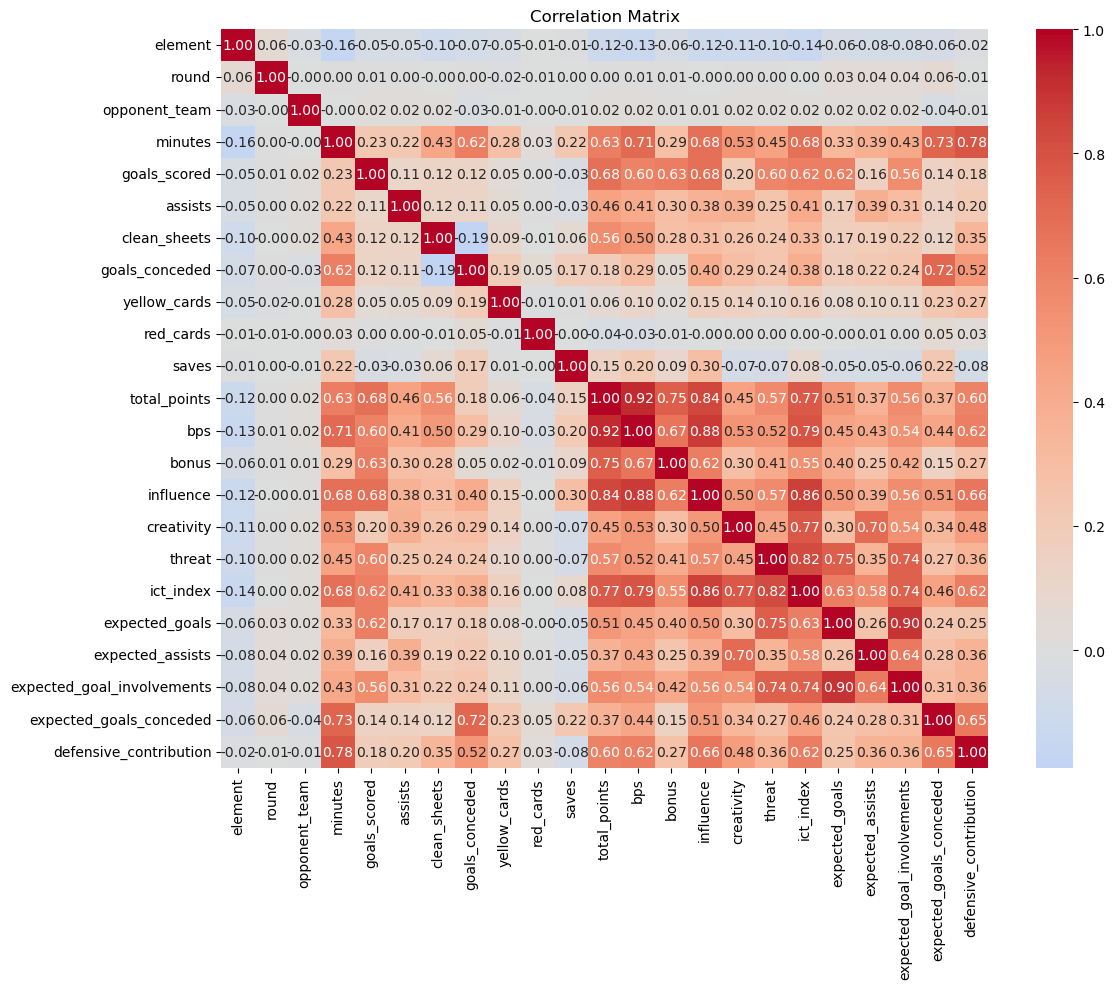

In [10]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 10))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## Performance by Position/Team

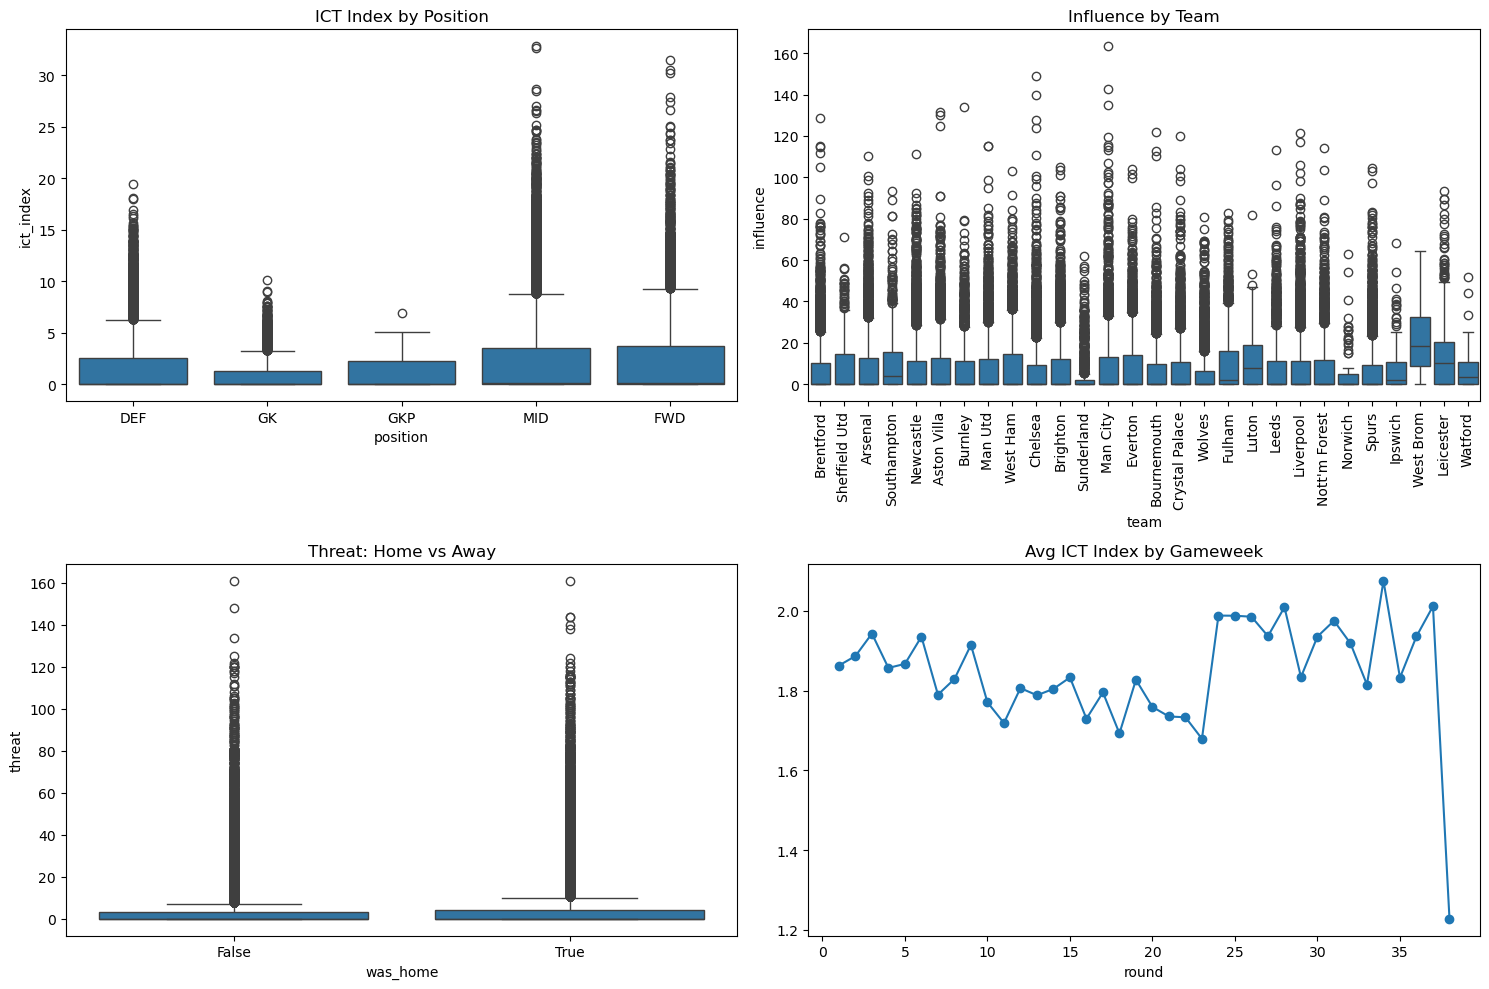

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.boxplot(data=df, x='position', y='ict_index', ax=axes[0,0])
axes[0,0].set_title('ICT Index by Position')

sns.boxplot(data=df, x='team', y='influence', ax=axes[0,1])
axes[0,1].set_title('Influence by Team')
axes[0,1].tick_params(axis='x', rotation=90)


sns.boxplot(data=df, x='was_home', y='threat', ax=axes[1,0])
axes[1,0].set_title('Threat: Home vs Away')

df.groupby('round')['ict_index'].mean().plot(ax=axes[1,1], marker='o')
axes[1,1].set_title('Avg ICT Index by Gameweek')
plt.tight_layout()
plt.show()

## Outliers and Summary Statistics

In [12]:
def find_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[column] < Q1 - 1.5*IQR) | (df[column] > Q3 + 1.5*IQR)]
    return len(outliers)

print("Outliers count:")
for var in ['ict_index', 'influence', 'threat']:
    print(f"{var}: {find_outliers(df, var)}")

summary = pd.DataFrame({
    'n_rows': len(df),
    'n_players': df['name'].nunique(),
    'mean_ict': df['ict_index'].mean(),
    'ict_std': df['ict_index'].std(),
    'missing_pct': df.isnull().sum().mean() / len(df) * 100
}, index=[0])

print("\nEDA Summary:\n", summary)

Outliers count:
ict_index: 5557
influence: 5590
threat: 10572

EDA Summary:
    n_rows  n_players  mean_ict   ict_std  missing_pct
0   70950        803  1.835886  3.055062     5.388982


## Most Goals by Team

Top 10 Teams by Goals Scored:
 team
Arsenal        290
Man City       284
Newcastle      276
Liverpool      247
Aston Villa    246
Brighton       233
Chelsea        208
Brentford      190
Man Utd        179
Spurs          178
Name: goals_scored, dtype: int64


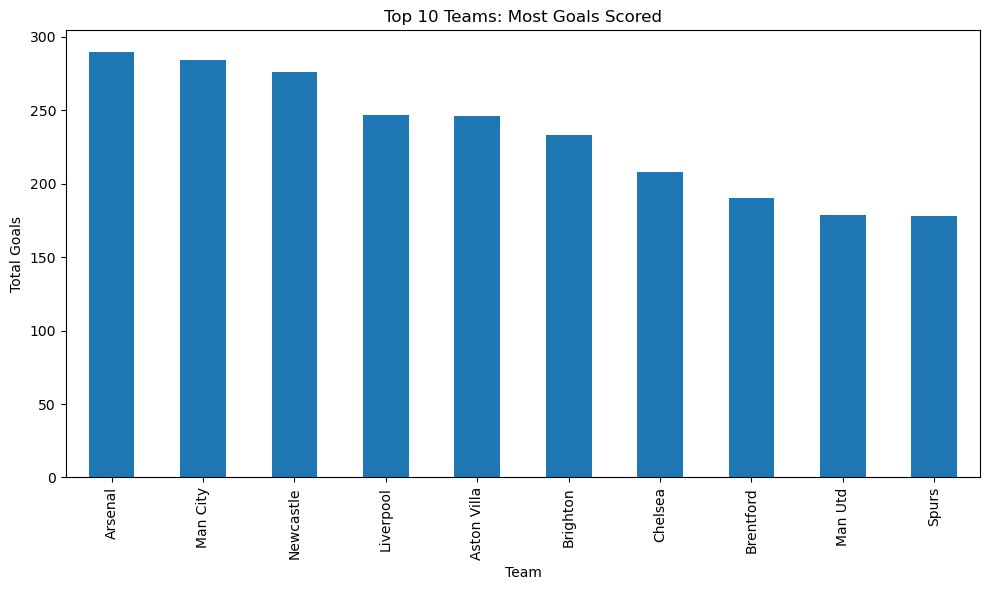

In [13]:
team_goals = df.groupby('team')['goals_scored'].sum().sort_values(ascending=False).head(10)
print("Top 10 Teams by Goals Scored:\n", team_goals)

plt.figure(figsize=(10, 6))
team_goals.plot(kind='bar')
plt.title('Top 10 Teams: Most Goals Scored')
plt.xlabel('Team')
plt.ylabel('Total Goals')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Most Goals by Player

Top 10 Players by Goals:
 name
Mohamed Salah     114
Erling Haaland    102
Ollie Watkins      83
Phil Foden         62
Jarrod Bowen       61
Alexander Isak     56
Bukayo Saka        55
Chris Wood         54
Callum Wilson      51
Bryan Mbeumo       49
Name: goals_scored, dtype: int64


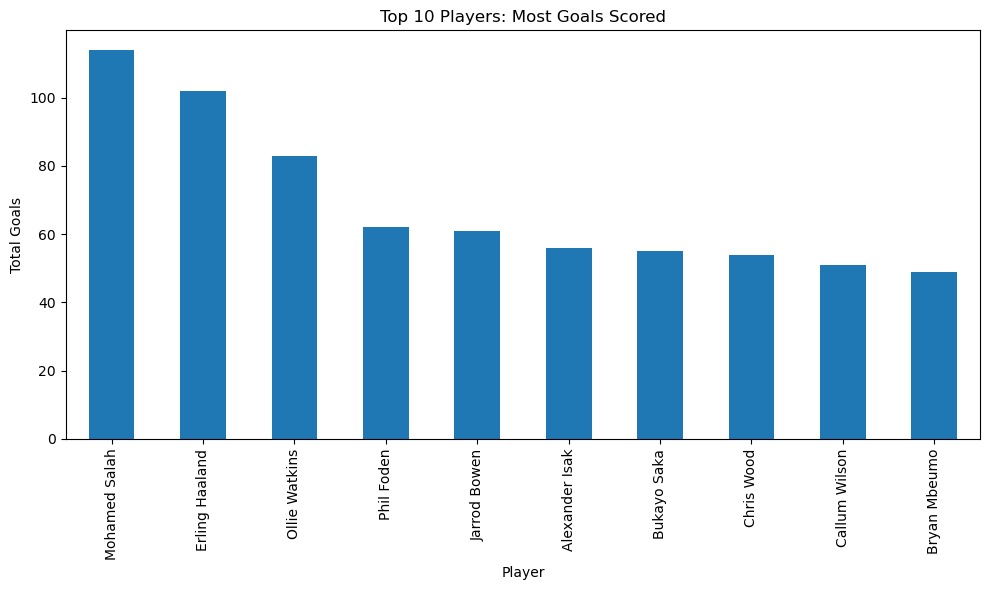

In [14]:
player_goals = df.groupby('name')['goals_scored'].sum().sort_values(ascending=False).head(10)
print("Top 10 Players by Goals:\n", player_goals)

plt.figure(figsize=(10, 6))
player_goals.plot(kind='bar')
plt.title('Top 10 Players: Most Goals Scored')
plt.xlabel('Player')
plt.ylabel('Total Goals')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Most Assists by Player

Top 10 Players by Assists:
 name
Mohamed Salah             66
Bukayo Saka               56
Jarrod Bowen              52
Ollie Watkins             48
James Maddison            46
Bruno Borges Fernandes    40
Martin Ødegaard           38
Leandro Trossard          37
Morgan Gibbs-White        36
Phil Foden                34
Name: assists, dtype: int64


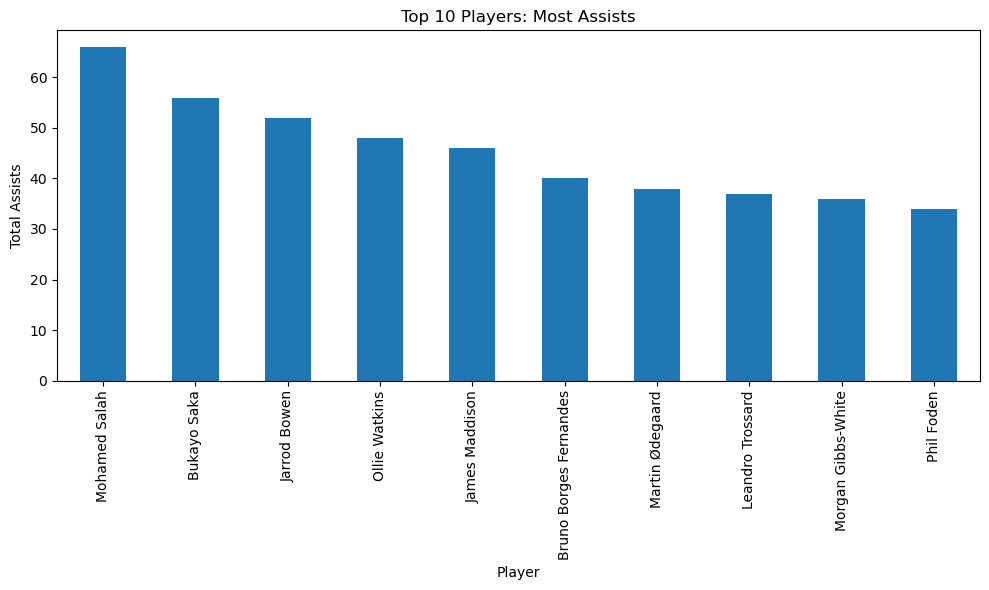

In [15]:
player_assists = df.groupby('name')['assists'].sum().sort_values(ascending=False).head(10)
print("Top 10 Players by Assists:\n", player_assists)

plt.figure(figsize=(10, 6))
player_assists.plot(kind='bar')
plt.title('Top 10 Players: Most Assists')
plt.xlabel('Player')
plt.ylabel('Total Assists')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Most FPL Points by Player

Top 10 Players by Total FPL Points:
 name
Mohamed Salah       1343
Ollie Watkins        973
Jarrod Bowen         959
Bukayo Saka          940
Phil Foden           850
Erling Haaland       812
Leandro Trossard     799
Jordan Pickford      750
Martin Ødegaard      731
Bryan Mbeumo         711
Name: total_points, dtype: int64


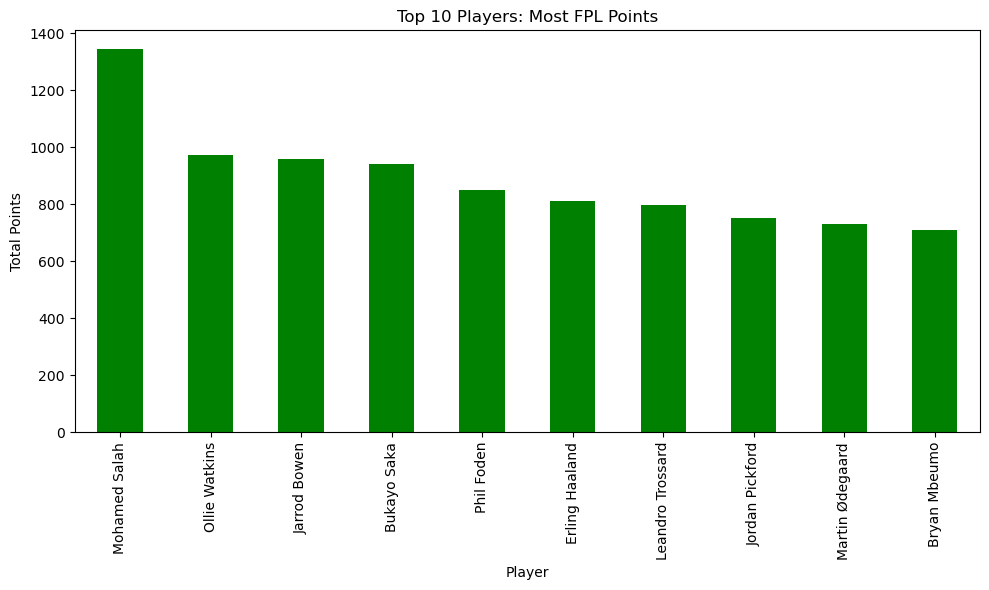

In [17]:
player_points = df.groupby('name')['total_points'].sum().sort_values(ascending=False).head(10)
print("Top 10 Players by Total FPL Points:\n", player_points)

plt.figure(figsize=(10, 6))
player_points.plot(kind='bar', color='green')
plt.title('Top 10 Players: Most FPL Points')
plt.xlabel('Player')
plt.ylabel('Total Points')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Goals vs FPL Points Scatter

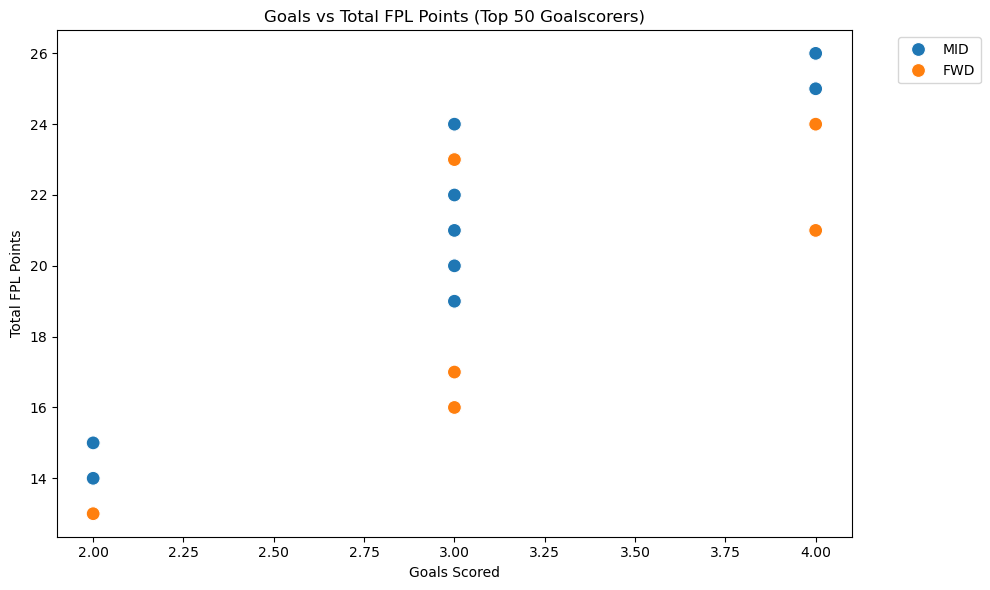

In [18]:
top_players = df.nlargest(50, 'goals_scored')
plt.figure(figsize=(10, 6))
sns.scatterplot(data=top_players, x='goals_scored', y='total_points', hue='position', s=100)
plt.title('Goals vs Total FPL Points (Top 50 Goalscorers)')
plt.xlabel('Goals Scored')
plt.ylabel('Total FPL Points')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Home vs Away Performance

Avg Performance Home vs Away:
           ict_index  influence    threat
was_home                                
False      1.740743   7.731813  4.744785
True       1.931034   7.882060  5.679343


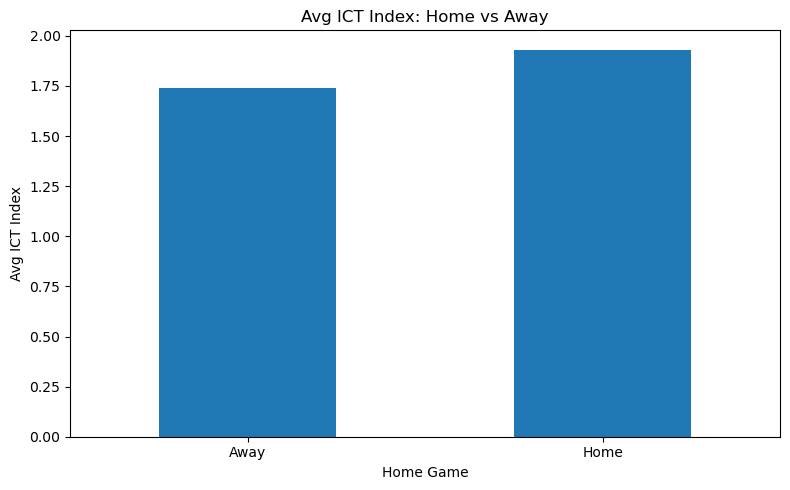

In [19]:
home_away = df.groupby('was_home')[['ict_index', 'influence', 'threat']].mean()
print("Avg Performance Home vs Away:\n", home_away)

plt.figure(figsize=(8, 5))
home_away['ict_index'].plot(kind='bar')
plt.title('Avg ICT Index: Home vs Away')
plt.xlabel('Home Game')
plt.ylabel('Avg ICT Index')
plt.xticks([0,1], ['Away', 'Home'], rotation=0)
plt.tight_layout()
plt.show()

## Summary Statistics Table

Performance Summary Statistics:

      influence  threat  ict_index  minutes
mean       7.81    5.21       1.84    34.16
std       13.39   12.43       3.06    40.40
min        0.00    0.00       0.00     0.00
max      163.40  161.00      32.80    90.00

Key Achievements:
    Best Gameweek  Max ICT  Max Influence  Max Threat  Avg Minutes
0              1     32.8          163.4       161.0        34.16


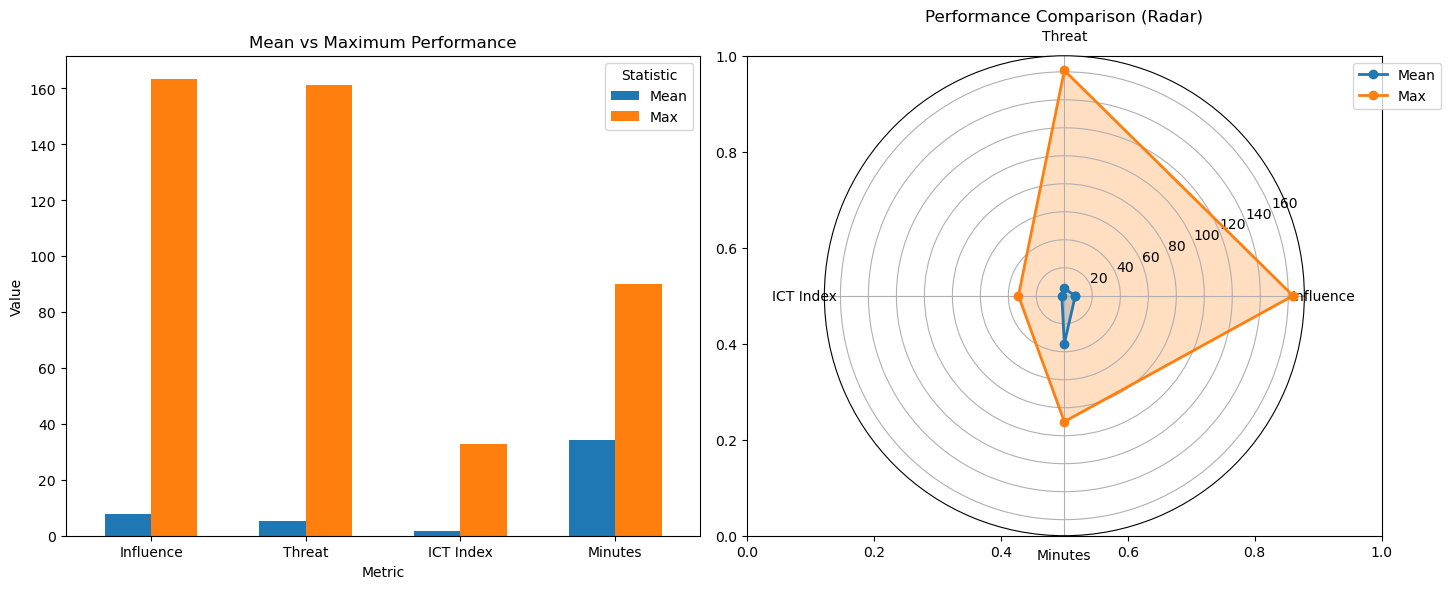

In [20]:
summary_stats = df[['influence', 'threat', 'ict_index', 'minutes']].agg(['mean', 'std', 'min', 'max'])
print("Performance Summary Statistics:\n")
print(summary_stats.round(2))

top_metrics = pd.DataFrame({
    'Best Gameweek': [df.loc[df['ict_index'].idxmax(), 'round']],
    'Max ICT': [df['ict_index'].max()],
    'Max Influence': [df['influence'].max()],
    'Max Threat': [df['threat'].max()],
    'Avg Minutes': [df['minutes'].mean()]
})

print("\nKey Achievements:\n", top_metrics.round(2))

comparison_data = pd.DataFrame({
    'Metric': ['Influence', 'Threat', 'ICT Index', 'Minutes'],
    'Mean': summary_stats.loc['mean', :],
    'Max': summary_stats.loc['max', :]
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

comparison_data.set_index('Metric')[['Mean', 'Max']].plot(kind='bar', ax=ax1, width=0.6)
ax1.set_title('Mean vs Maximum Performance')
ax1.set_ylabel('Value')
ax1.legend(title='Statistic')
ax1.tick_params(axis='x', rotation=0)

categories = list(comparison_data['Metric'])
N = len(categories)
angles = [n / float(N) * 2 * math.pi for n in range(N)]
angles += angles[:1]

ax2 = plt.subplot(122, projection='polar')
mean_values = list(comparison_data['Mean']) + list(comparison_data['Mean'])[:1]
max_values = list(comparison_data['Max']) + list(comparison_data['Max'])[:1]

ax2.plot(angles, mean_values, 'o-', linewidth=2, label='Mean')
ax2.fill(angles, mean_values, alpha=0.25)
ax2.plot(angles, max_values, 'o-', linewidth=2, label='Max')
ax2.fill(angles, max_values, alpha=0.25)

ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories)
ax2.set_ylim(0)
ax2.set_title('Performance Comparison (Radar)')
ax2.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

plt.tight_layout()
plt.show()